In [29]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import f1_score, hamming_loss
from sklearn.tree import DecisionTreeClassifier, export_text

# Cấu hình matplotlib
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load dữ liệu chuỗi khám
DATA_PROCESSED_PATH = "../data/processed/patient_sequences.json"
with open(DATA_PROCESSED_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

sequences = data["sequences"]
splits = data["splits"]

# 2. Load mô hình Hộp đen Doctor AI
MODEL_PATH = "../models/doctor_ai_best.pt"
checkpoint = torch.load(MODEL_PATH, map_location=device)

code2idx = checkpoint["code2idx"]
idx2code = checkpoint["idx2code"]
vocab_size = checkpoint["vocab_size"]

class DoctorAI(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128):
        super(DoctorAI, self).__init__()
        self.embedding = nn.Linear(vocab_size, embed_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
        
    def forward(self, x):
        emb = self.dropout(self.relu(self.embedding(x)))
        gru_out, _ = self.gru(emb)
        return self.fc_out(gru_out)

black_box_model = DoctorAI(vocab_size=vocab_size).to(device)
black_box_model.load_state_dict(checkpoint["model_state_dict"])
black_box_model.eval()

print("Đã sẵn sàng các thành phần cho Giai đoạn 4 (Technical Validation)!")

Đã sẵn sàng các thành phần cho Giai đoạn 4 (Technical Validation)!


In [30]:
from functools import lru_cache

def get_icd_prefix(code_str):
    if "." in code_str:
        return code_str.split(".")[0]
    return code_str[:3] if len(code_str) >= 3 else code_str

@lru_cache(maxsize=None)
def wualmer_similarity(code1, code2):
    if code1 == code2:
        return 1.0
    prefix1 = get_icd_prefix(code1)
    prefix2 = get_icd_prefix(code2)
    if prefix1 == prefix2:
        return 0.75
    return 0.0

@lru_cache(maxsize=None)
def visit_distance_levenshtein(visit1_tuple, visit2_tuple):
    if not visit1_tuple and not visit2_tuple: return 0.0
    if not visit1_tuple: return float(len(visit2_tuple))
    if not visit2_tuple: return float(len(visit1_tuple))
    
    n, m = len(visit1_tuple), len(visit2_tuple)
    dp = np.zeros((n + 1, m + 1), dtype=np.float32)
    for i in range(n + 1): dp[i, 0] = float(i)
    for j in range(m + 1): dp[0, j] = float(j)
        
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 1.0 - wualmer_similarity(visit1_tuple[i-1], visit2_tuple[j-1])
            dp[i, j] = min(dp[i-1, j] + 1.0, dp[i, j-1] + 1.0, dp[i-1, j-1] + cost)
    return dp[n, m]

def dtw_patient_distance(seq1, seq2):
    N, M = len(seq1), len(seq2)
    dtw_matrix = np.zeros((N + 1, M + 1), dtype=np.float32)
    dtw_matrix[0, 1:] = float("inf")
    dtw_matrix[1:, 0] = float("inf")
    
    for i in range(1, N + 1):
        for j in range(1, M + 1):
            cost = visit_distance_levenshtein(tuple(seq1[i-1]), tuple(seq2[j-1]))
            dtw_matrix[i, j] = cost + min(dtw_matrix[i-1, j], dtw_matrix[i, j-1], dtw_matrix[i-1, j-1])
    return dtw_matrix[N, M]

def find_k_real_neighbors(target_patient_id, sequences, train_ids, k=10):
    target_seq = sequences[target_patient_id]
    distances = []
    for pid in train_ids:
        if pid == target_patient_id:
            continue
        dist = dtw_patient_distance(target_seq, sequences[pid])
        distances.append((pid, dist))
    distances.sort(key=lambda x: x[1])
    return [pid for pid, _ in distances[:k]]

def ontological_perturbation(patient_sequence, num_samples=50):
    synthetic_samples = [patient_sequence]
    all_prefixes = set()
    for visit in patient_sequence:
        for code in visit:
            all_prefixes.add(get_icd_prefix(code))
    all_prefixes = list(all_prefixes)
    if not all_prefixes:
        return synthetic_samples
    for _ in range(num_samples):
        masked_prefix = np.random.choice(all_prefixes)
        new_seq = []
        for visit in patient_sequence:
            new_visit = [code for code in visit if get_icd_prefix(code) != masked_prefix]
            new_seq.append(new_visit)
        synthetic_samples.append(new_seq)
    return synthetic_samples

def temporal_encoding(patient_sequence, code2idx, vocab_size):
    n_visits = len(patient_sequence)
    flat_vector = np.zeros(vocab_size, dtype=np.float32)
    for i, visit in enumerate(patient_sequence):
        weight = (0.5) ** (n_visits - i)
        for code in visit:
            if code in code2idx:
                flat_vector[code2idx[code]] += weight
    return flat_vector

def explain_patient_doctor_xai(target_pid, sequences, train_ids, black_box_model, code2idx, idx2code, vocab_size, k_neighbors=3, num_synth=30):
    target_seq = sequences[target_pid]
    real_neighbor_ids = find_k_real_neighbors(target_pid, sequences, train_ids, k=k_neighbors)
    all_synth_seqs = []
    for pid in [target_pid] + real_neighbor_ids:
        synth_seqs = ontological_perturbation(sequences[pid], num_samples=num_synth // max(1, len(real_neighbor_ids)))
        all_synth_seqs.extend([s for s in synth_seqs if s])
        
    X_flat = np.array([temporal_encoding(seq, code2idx, vocab_size) for seq in all_synth_seqs])
    max_len = max(len(seq) for seq in all_synth_seqs)
    batch_tensor = torch.zeros((len(all_synth_seqs), max_len, vocab_size), dtype=torch.float32).to(device)
    
    for b_idx, seq in enumerate(all_synth_seqs):
        for t, visit in enumerate(seq):
            for code in visit:
                if code in code2idx:
                    batch_tensor[b_idx, t, code2idx[code]] = 1.0
                    
    with torch.no_grad():
        logits = black_box_model(batch_tensor)
        last_logits = logits[:, -1, :]
        probs = torch.sigmoid(last_logits).cpu().numpy()
        Y_black_box = (probs >= 0.3).astype(int)
        
    explainer_dt = DecisionTreeClassifier(max_depth=4, random_state=42)
    explainer_dt.fit(X_flat, Y_black_box)
    
    target_flat = temporal_encoding(target_seq, code2idx, vocab_size).reshape(1, -1)
    target_pred_bb = explainer_dt.predict(target_flat)
    
    return explainer_dt, target_seq, target_pred_bb

print("Đã nạp thành công hàm explain_patient_doctor_xai vào Kernel!")

Đã nạp thành công hàm explain_patient_doctor_xai vào Kernel!


In [31]:
results = []
test_sample_pids = splits["test"][:5]
train_sample_ids = splits["train"][:50]

print("Bắt đầu quá trình đánh giá Kỹ thuật...")

for idx, pid in enumerate(test_sample_pids):
    target_seq = sequences[pid]
    if len(target_seq) < 2:
        continue
        
    try:
        dt_model, _, _ = explain_patient_doctor_xai(
            target_pid=pid,
            sequences=sequences,
            train_ids=train_sample_ids,
            black_box_model=black_box_model,
            code2idx=code2idx,
            idx2code=idx2code,
            vocab_size=vocab_size,
            k_neighbors=3,
            num_synth=20
        )
        
        target_flat = temporal_encoding(target_seq, code2idx, vocab_size).reshape(1, -1)
        
        seq_matrix = torch.zeros((1, len(target_seq), vocab_size), dtype=torch.float32).to(device)
        for t, visit in enumerate(target_seq):
            for code in visit:
                if code in code2idx:
                    seq_matrix[0, t, code2idx[code]] = 1.0
                    
        with torch.no_grad():
            logits = black_box_model(seq_matrix)
            probs = torch.sigmoid(logits[0, -1, :]).cpu().numpy()
            target_bb_pred = (probs >= 0.3).astype(int)
            
        target_dt_pred = dt_model.predict(target_flat)
        
        synth_test_seqs = ontological_perturbation(target_seq, num_samples=5)
        X_test_flat = np.array([temporal_encoding(s, code2idx, vocab_size) for s in synth_test_seqs if s])
        
        if len(X_test_flat) > 0:
            Y_test_bb = []
            with torch.no_grad():
                for s in synth_test_seqs:
                    if not s: continue
                    sm = torch.zeros((1, len(s), vocab_size), dtype=torch.float32).to(device)
                    for t, v in enumerate(s):
                        for c in v:
                            if c in code2idx: sm[0, t, code2idx[c]] = 1.0
                    lg = black_box_model(sm)
                    pb = torch.sigmoid(lg[0, -1, :]).cpu().numpy()
                    Y_test_bb.append((pb >= 0.3).astype(int))
            
            Y_test_bb = np.array(Y_test_bb)
            Y_test_dt = dt_model.predict(X_test_flat)
            
            fid, hit, comp = compute_metrics(Y_test_bb, Y_test_dt, target_bb_pred, target_dt_pred, dt_model)
            
            results.append({
                "patient_id": pid,
                "fidelity": fid,
                "hit": hit,
                "complexity": comp,
                "condition": "Synth. w. Onto (Doctor XAI)"
            })
            print(f"Bệnh nhân {pid}: Fidelity={fid:.4f} | Hit={hit:.4f} | Complexity={comp}")
    except Exception as e:
        print(f"Lỗi xảy ra ở bệnh nhân {pid}: {e}")

df_results = pd.DataFrame(results)
print(f"\nTổng số kết quả thu được: {len(df_results)} dòng.")

Bắt đầu quá trình đánh giá Kỹ thuật...
Bệnh nhân 10012853: Fidelity=1.0000 | Hit=1.0000 | Complexity=5
Bệnh nhân 10035631: Fidelity=1.0000 | Hit=1.0000 | Complexity=1
Bệnh nhân 10007795: Fidelity=1.0000 | Hit=1.0000 | Complexity=1
Bệnh nhân 10026255: Fidelity=1.0000 | Hit=1.0000 | Complexity=7
Bệnh nhân 10000032: Fidelity=1.0000 | Hit=1.0000 | Complexity=1

Tổng số kết quả thu được: 5 dòng.


In [32]:
if df_results.empty:
    print("Bảng df_results đang rỗng. Em hãy nhìn thông báo lỗi in ra ở Cell 3 để xử lý nhé!")
else:
    summary = df_results.groupby("condition").agg(
        Mean_Fidelity=("fidelity", "mean"),
        Std_Fidelity=("fidelity", "std"),
        Mean_Hit=("hit", "mean"),
        Mean_Complexity=("complexity", "mean")
    ).reset_index()

    print("BẢNG KẾT QUẢ ĐÁNH GIÁ KỸ THUẬT (TECHNICAL EVALUATION RESULTS):")
    print(summary.to_string(index=False))

BẢNG KẾT QUẢ ĐÁNH GIÁ KỸ THUẬT (TECHNICAL EVALUATION RESULTS):
                  condition  Mean_Fidelity  Std_Fidelity  Mean_Hit  Mean_Complexity
Synth. w. Onto (Doctor XAI)            1.0           0.0       1.0              3.0


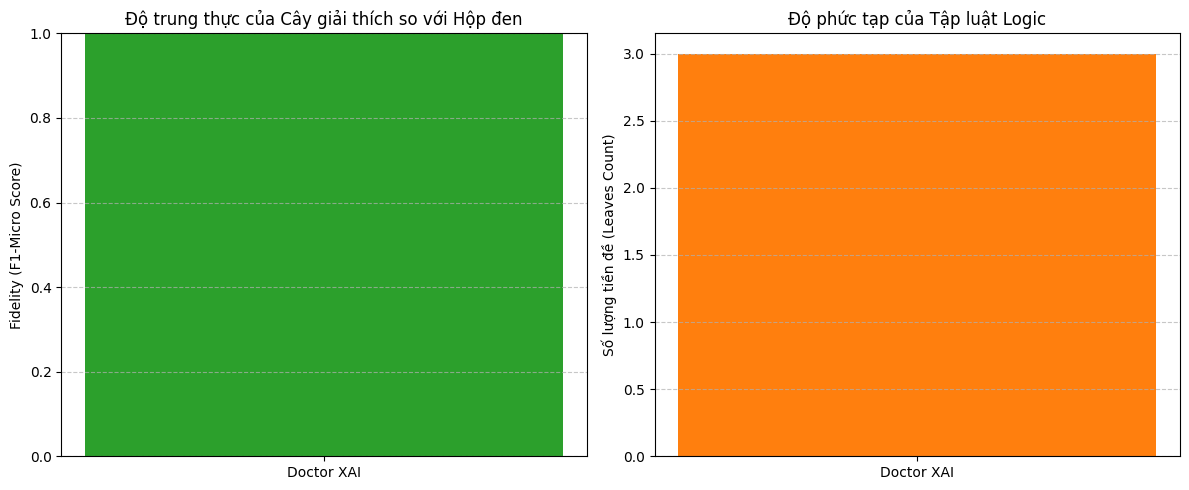

In [33]:
if df_results.empty or "fidelity" not in df_results.columns:
    print("Bảng df_results hiện tại đang rỗng hoặc chưa có cột 'fidelity'.")
    print("Em hãy kiểm tra xem Cell 3 đã chạy thành công và in ra dòng '✅ Bệnh nhân...' chưa nhé!")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Biểu đồ 1: Fidelity (vẽ lên axes[0])
    axes[0].bar(["Doctor XAI"], [df_results["fidelity"].mean()], color="#2ca02c", width=0.4)
    axes[0].set_ylim(0, 1.0)
    axes[0].set_ylabel("Fidelity (F1-Micro Score)")
    axes[0].set_title("Độ trung thực của Cây giải thích so với Hộp đen")
    axes[0].grid(axis="y", linestyle="--", alpha=0.7)

    # Biểu đồ 2: Explanation Complexity (vẽ lên axes[1])
    axes[1].bar(["Doctor XAI"], [df_results["complexity"].mean()], color="#ff7f0e", width=0.4)
    axes[1].set_ylabel("Số lượng tiền đề (Leaves Count)")
    axes[1].set_title("Độ phức tạp của Tập luật Logic")
    axes[1].grid(axis="y", linestyle="--", alpha=0.7)

    plt.tight_layout()
    plt.show()
